<a href="https://colab.research.google.com/github/Ayush-aw4/Mars_Rover_Terrain_Segmentation/blob/main/Mars_Rover.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q datasets matplotlib pillow

In [2]:
import torch

print("PyTorch version:", torch.__version__)

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [3]:
from datasets import load_dataset

train_stream = load_dataset(
    "hassanjbara/AI4MARS",
    split="train",
    streaming = True
)

print("Dataset loaded successfully")

README.md:   0%|          | 0.00/3.14k [00:00<?, ?B/s]

Dataset loaded successfully


In [4]:
sample = None

for row in train_stream:
  if row["has_labels"] and row["label_mask"] is not None:
    sample = row
    break

print("Available columns:", sample.keys())

print("Has labels:", sample["has_labels"])

print("Has masks:", sample["has_masks"])

Available columns: dict_keys(['image', 'label_mask', 'rover_mask', 'range_mask', 'has_masks', 'has_labels'])
Has labels: True
Has masks: True


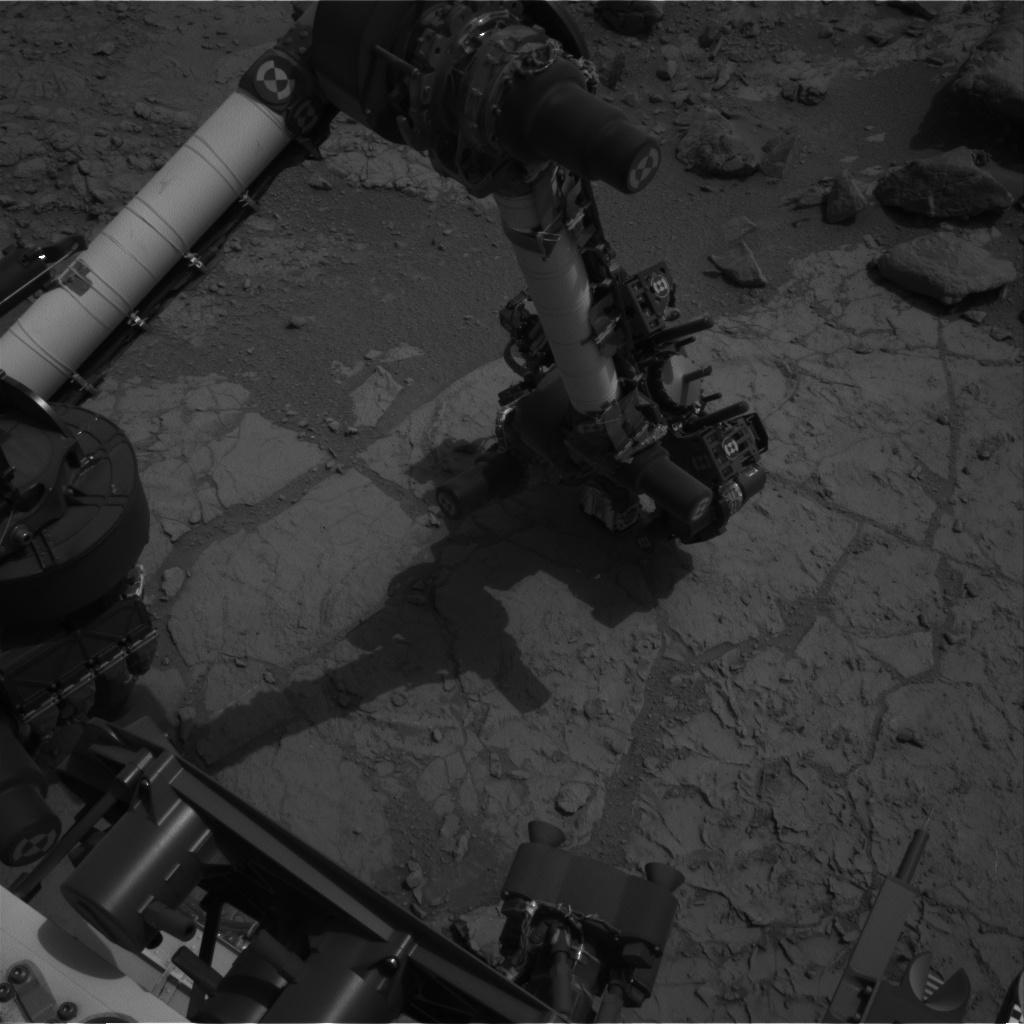

In [5]:
from IPython.display import display

display(sample["image"])

In [6]:
import numpy as np
from PIL import Image

mask = np.array(sample["label_mask"])

if mask.ndim == 3:
  mask = mask[..., 0]

print("Mask shape: ",mask.shape)
print("Unique pixel values: ",np.unique(mask))

Mask shape:  (1024, 1024)
Unique pixel values:  [  0   1   3 255]


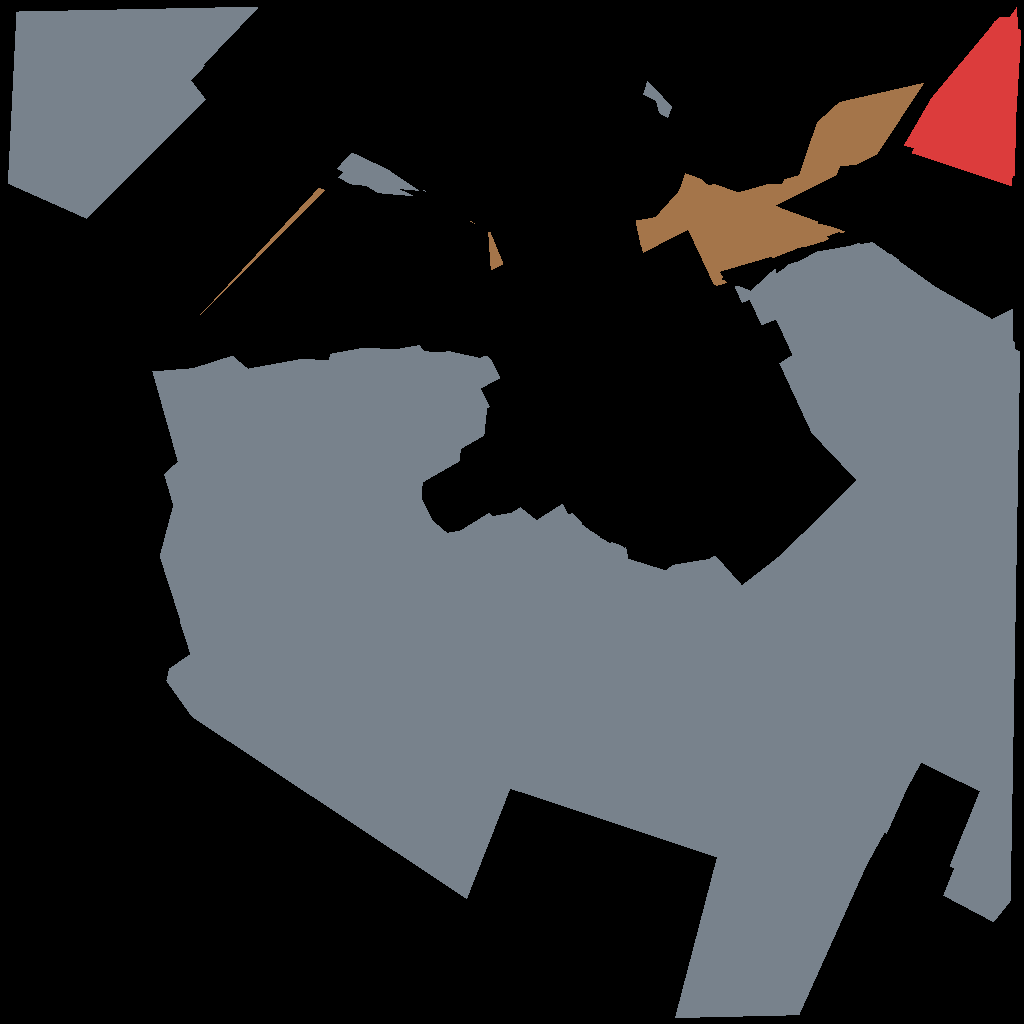

In [7]:
colors = np.array([
    [164,117,74], #Soil
    [120,130,140],  #Bedrock
    [238,190,70], #Sand
    [220,60,60] #Big Rock
],dtype=np.uint8)

colored_mask = np.zeros(
    (mask.shape[0],mask.shape[1],3),
    dtype=np.uint8
)

for class_id in range(4):
  colored_mask[mask == class_id] = colors[class_id]
colored_mask[mask==255] = [0,0,0]
display(Image.fromarray(colored_mask))

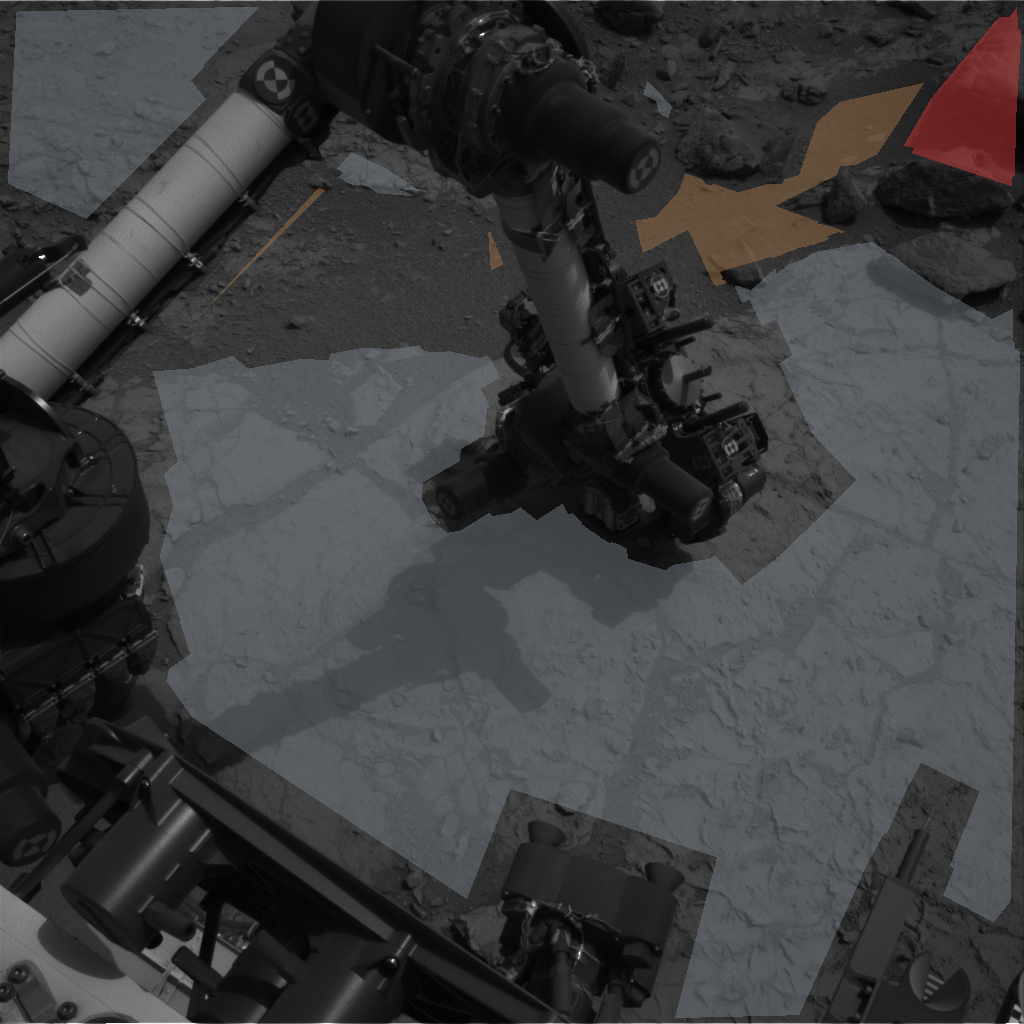

In [8]:
image = np.array(sample["image"].convert("RGB"))

valid = mask != 255

overlay = image.copy()

overlay[valid] = (
    0.55 * image[valid] +
    0.45 * colored_mask[valid]
).astype(np.uint8)

display(Image.fromarray(overlay))

In [9]:
values,counts = np.unique(
    mask,
    return_counts=True
)
class_names = {
    0: "Soil",
    1: "Bedrock",
    2: "Sand",
    3: "Big Rock",
    255: "Unlabelled"
}

total_pixels = mask.size

print("Total pixels:", total_pixels)
print("\nPixel distribution:\n")

for value, count in zip(values,counts):
  percentage = (count/total_pixels)*100

  print(
      f"{class_names[value]:12s} | "
      f"Pixels: {count:8d} | "
      f"Percentage: {percentage:.2f}%"
  )


Total pixels: 1048576

Pixel distribution:

Soil         | Pixels:    17993 | Percentage: 1.72%
Bedrock      | Pixels:   408609 | Percentage: 38.97%
Big Rock     | Pixels:    11645 | Percentage: 1.11%
Unlabelled   | Pixels:   610329 | Percentage: 58.21%


In [10]:
import numpy as np

for key in ("rover_mask","range_mask"):

  current_mask = sample[key]

  print("\nMask name:",key)

  if current_mask is None:
    print("Mask is missing")
    continue

  mask_array = np.array(current_mask)

  print("Original shape:",mask_array.shape)
  print("Data type:",mask_array.dtype)

  if mask_array.ndim == 3:
        mask_array = mask_array[..., 0]

  print("Processed shape:", mask_array.shape)

  values, counts = np.unique(
        mask_array,
        return_counts=True
    )

  print("Unique values:", values)

  print("Pixel counts:", counts)

  print(
        "Percentage of pixels to ignore:",
        round(np.mean(mask_array > 0) * 100, 2),
        "%"
    )


Mask name: rover_mask
Original shape: (1024, 1024)
Data type: uint8
Processed shape: (1024, 1024)
Unique values: [0 1]
Pixel counts: [559642 488934]
Percentage of pixels to ignore: 46.63 %

Mask name: range_mask
Original shape: (1024, 1024)
Data type: uint8
Processed shape: (1024, 1024)
Unique values: [0]
Pixel counts: [1048576]
Percentage of pixels to ignore: 0.0 %


ROVER MASK


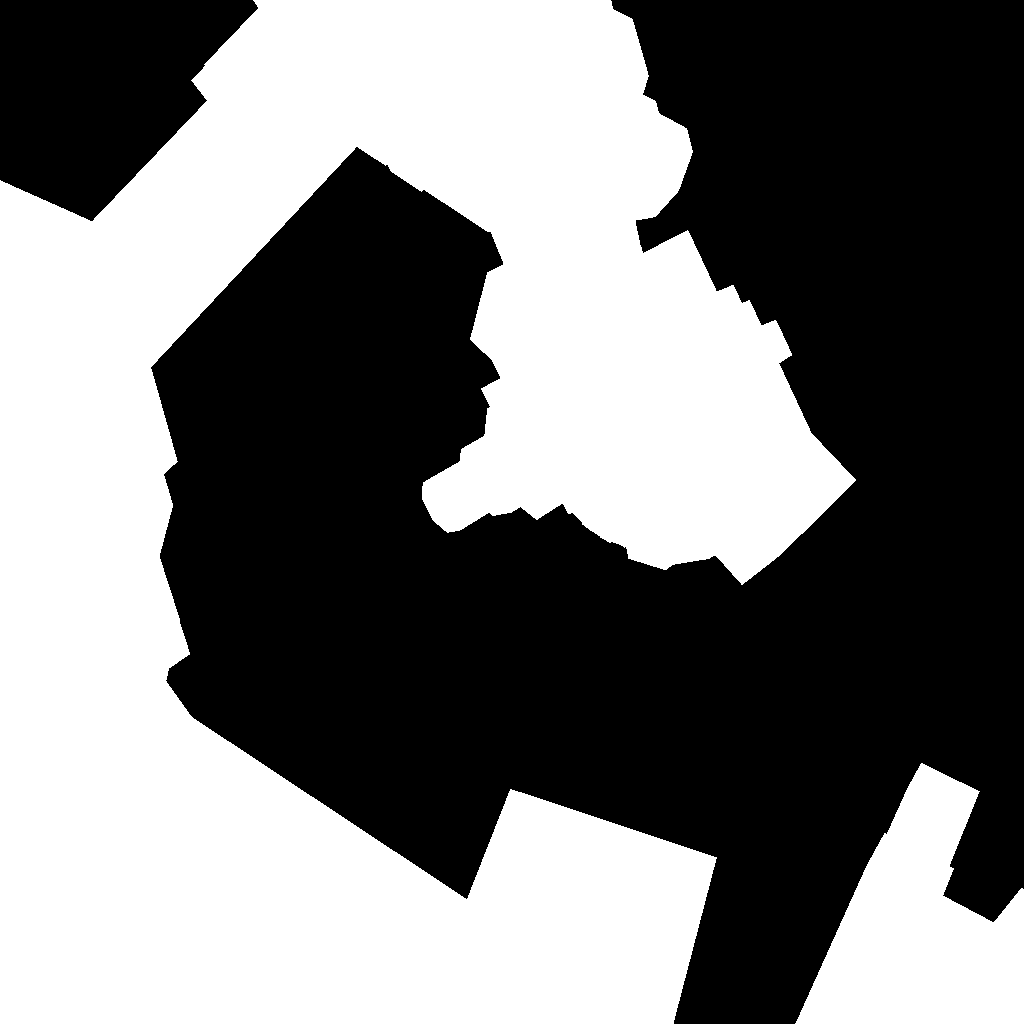

RANGE MASK


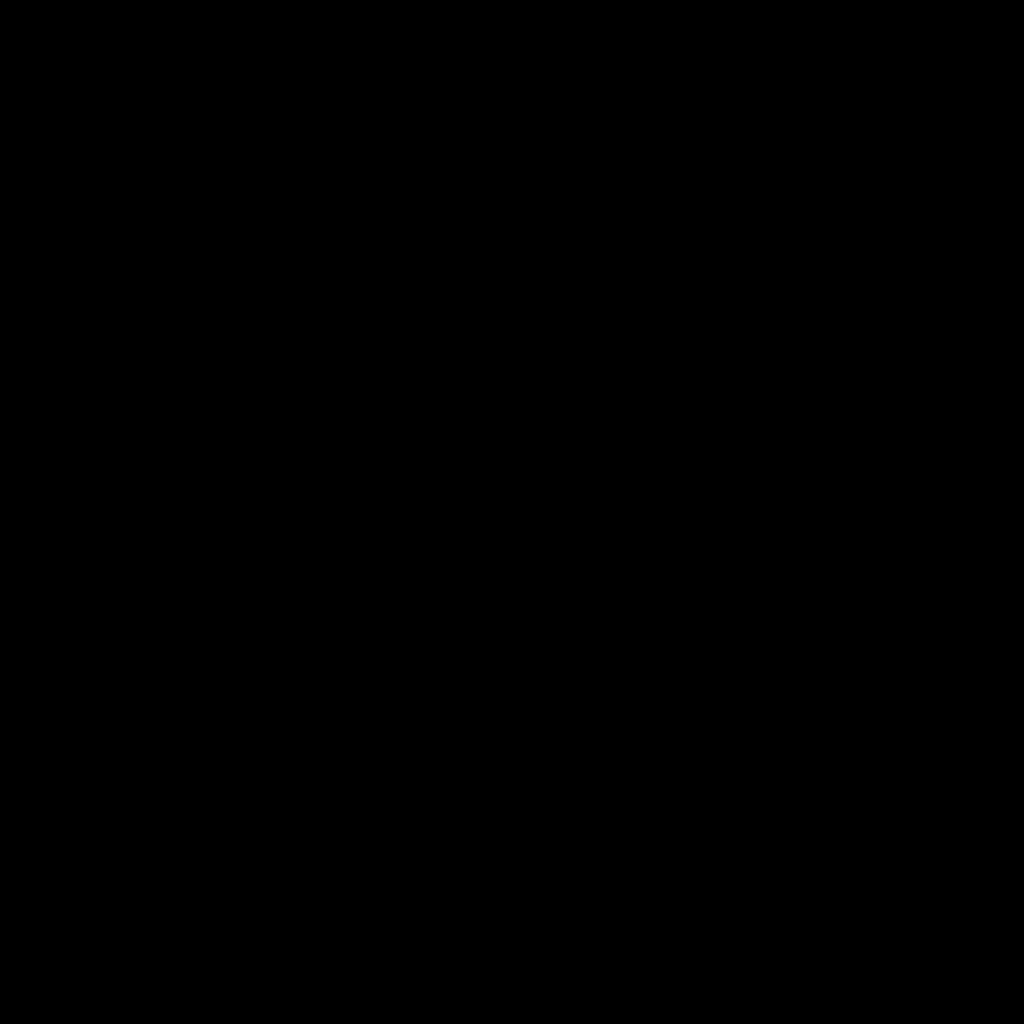

In [11]:
from PIL import Image
import numpy as np

rover_mask = np.array(sample["rover_mask"])

range_mask = np.array(sample["range_mask"])

print("ROVER MASK")

display(
    Image.fromarray(
        (rover_mask * 255).astype(np.uint8)
    )
)

print("RANGE MASK")

display(
    Image.fromarray(
        (range_mask * 255).astype(np.uint8)
    )
)

In [12]:
label = np.array(sample["label_mask"])

if label.ndim == 3:
    label = label[..., 0]

rover_ignore = rover_mask > 0
range_ignore = range_mask > 0

valid_before = label != 255

rover_affected = np.sum(
    valid_before & rover_ignore
)

range_affected = np.sum(
    valid_before & range_ignore
)

print("Labelled pixels before preprocessing:",
      np.sum(valid_before))

print("Labelled pixels inside rover region:",
      rover_affected)

print("Labelled pixels inside range region:",
      range_affected)

Labelled pixels before preprocessing: 438247
Labelled pixels inside rover region: 0
Labelled pixels inside range region: 0


In [13]:
import numpy as np

IGNORE = 255

def prepare(row):

    image = np.array(
        row["image"].convert("RGB")
    )

    label = np.array(row["label_mask"])

    if label.ndim == 3:
        label = label[..., 0]

    label = label.astype(np.int64, copy=True)

    if image.shape[:2] != label.shape:
        raise ValueError("Image and label dimensions do not match")

    for key in ("rover_mask", "range_mask"):

        if row[key] is not None:

            mask = np.array(row[key])

            if mask.ndim == 3:
                mask = mask[..., 0]

            if mask.shape != label.shape:
                raise ValueError(f"{key} dimensions do not match label")

            label[mask > 0] = IGNORE

    return image, label

In [14]:
processed_image, processed_label = prepare(sample)

print("IMAGE INFORMATION")

print("Shape:", processed_image.shape)
print("Data type:", processed_image.dtype)

print("\nLABEL INFORMATION")

print("Shape:", processed_label.shape)
print("Data type:", processed_label.dtype)

print("Unique values:", np.unique(processed_label))

print("\nPIXEL COUNTS")

values, counts = np.unique(
    processed_label,
    return_counts=True
)

for value, count in zip(values, counts):

    print(f"Class {value}: {count} pixels")

IMAGE INFORMATION
Shape: (1024, 1024, 3)
Data type: uint8

LABEL INFORMATION
Shape: (1024, 1024)
Data type: int64
Unique values: [  0   1   3 255]

PIXEL COUNTS
Class 0: 17993 pixels
Class 1: 408609 pixels
Class 3: 11645 pixels
Class 255: 610329 pixels


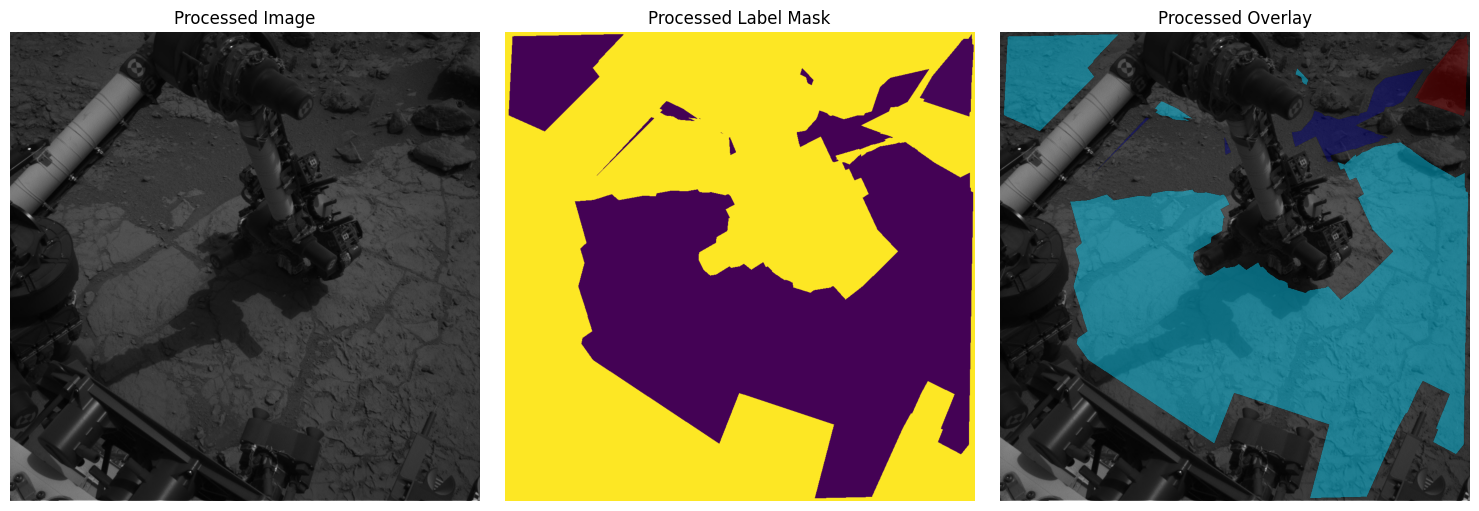

In [15]:
from PIL import Image
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(processed_image)
plt.title("Processed Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(processed_label)
plt.title("Processed Label Mask")
plt.axis("off")

plt.subplot(1, 3, 3)

plt.imshow(processed_image)
plt.imshow(
    np.ma.masked_where(
        processed_label == IGNORE,
        processed_label
    ),
    alpha=0.45,
    cmap="jet",
    vmin=0,
    vmax=3
)

plt.title("Processed Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
from PIL import Image
import numpy as np

toy_row = {

    "image": Image.fromarray(
        np.zeros((2, 3, 3), dtype=np.uint8)
    ),

    "label_mask": np.array([
        [0, 1, 2],
        [3, 255, 0]
    ], dtype=np.uint8),

    "rover_mask": np.array([
        [0, 1, 0],
        [0, 0, 0]
    ], dtype=np.uint8),

    "range_mask": np.array([
        [0, 0, 0],
        [1, 0, 0]
    ], dtype=np.uint8)
}

In [17]:
toy_image, toy_label = prepare(toy_row)

print("Original label:")
print(toy_row["label_mask"])

print("\nProcessed label:")
print(toy_label)

Original label:
[[  0   1   2]
 [  3 255   0]]

Processed label:
[[  0 255   2]
 [255 255   0]]


In [18]:
expected = np.array([
    [0, 255, 2],
    [255, 255, 0]
], dtype=np.int64)

assert np.array_equal(toy_label, expected)

assert toy_image.shape == (2, 3, 3)

assert toy_label.dtype == np.int64

print("All preprocessing tests passed!")

All preprocessing tests passed!


In [19]:
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   92M  113G   1% /


# Training and Validation Preparation

In [20]:
from datasets import load_dataset

train_data = load_dataset(
    "hassanjbara/AI4MARS",
    split="train"
)

print("Dataset loaded successfully!")

print("Dataset type:", type(train_data))

print("Total training images:", len(train_data))

print("Available columns:", train_data.column_names)

data/train-00000-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  475MB            

data/train-00000-of-00013.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  476MB            

data/train-00001-of-00013.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00013.parquet: reconstructing file:   0%|          |  0.00B /  471MB            

data/train-00002-of-00013.parquet: downloading bytes:           |  0.00B            

... (27 outputs left out)

Generating test_min1 split:   0%|          | 0/322 [00:00<?, ? examples/s]

Generating test_min2 split:   0%|          | 0/322 [00:00<?, ? examples/s]

Generating test_min3 split:   0%|          | 0/322 [00:00<?, ? examples/s]

Dataset loaded successfully!
Dataset type: <class 'datasets.arrow_dataset.Dataset'>
Total training images: 18130
Available columns: ['image', 'label_mask', 'rover_mask', 'range_mask', 'has_masks', 'has_labels']


In [21]:
has_labels = train_data["has_labels"]

labelled_indices = [
    index
    for index, has_label in enumerate(has_labels)
    if has_label
]

unlabelled_count = len(train_data) - len(labelled_indices)

print("Total images:", len(train_data))

print("Images containing labels:", len(labelled_indices))

print("Images without labels:", unlabelled_count)

Total images: 18130
Images containing labels: 16064
Images without labels: 2066


In [22]:
labelled_data = train_data.select(labelled_indices)

print("Labelled dataset created!")

print("Total samples:", len(labelled_data))

print("Dataset type:", type(labelled_data))

Labelled dataset created!
Total samples: 16064
Dataset type: <class 'datasets.arrow_dataset.Dataset'>


In [23]:
splits = labelled_data.train_test_split(
    test_size=0.10,
    shuffle=True,
    seed=42
)

train_dataset = splits["train"]

val_dataset = splits["test"]

In [24]:
print("TRAINING DATASET")
print("Images:", len(train_dataset))

print("\nVALIDATION DATASET")
print("Images:", len(val_dataset))

print("\nTOTAL")
print("Images:", len(train_dataset) + len(val_dataset))

TRAINING DATASET
Images: 14457

VALIDATION DATASET
Images: 1607

TOTAL
Images: 16064


In [25]:
print(
    "All training samples labelled:",
    all(train_dataset["has_labels"])
)

print(
    "All validation samples labelled:",
    all(val_dataset["has_labels"])
)

All training samples labelled: True
All validation samples labelled: True


Image shape: (1024, 1024, 3)
Label shape: (1024, 1024)
Unique label values: [  1 255]


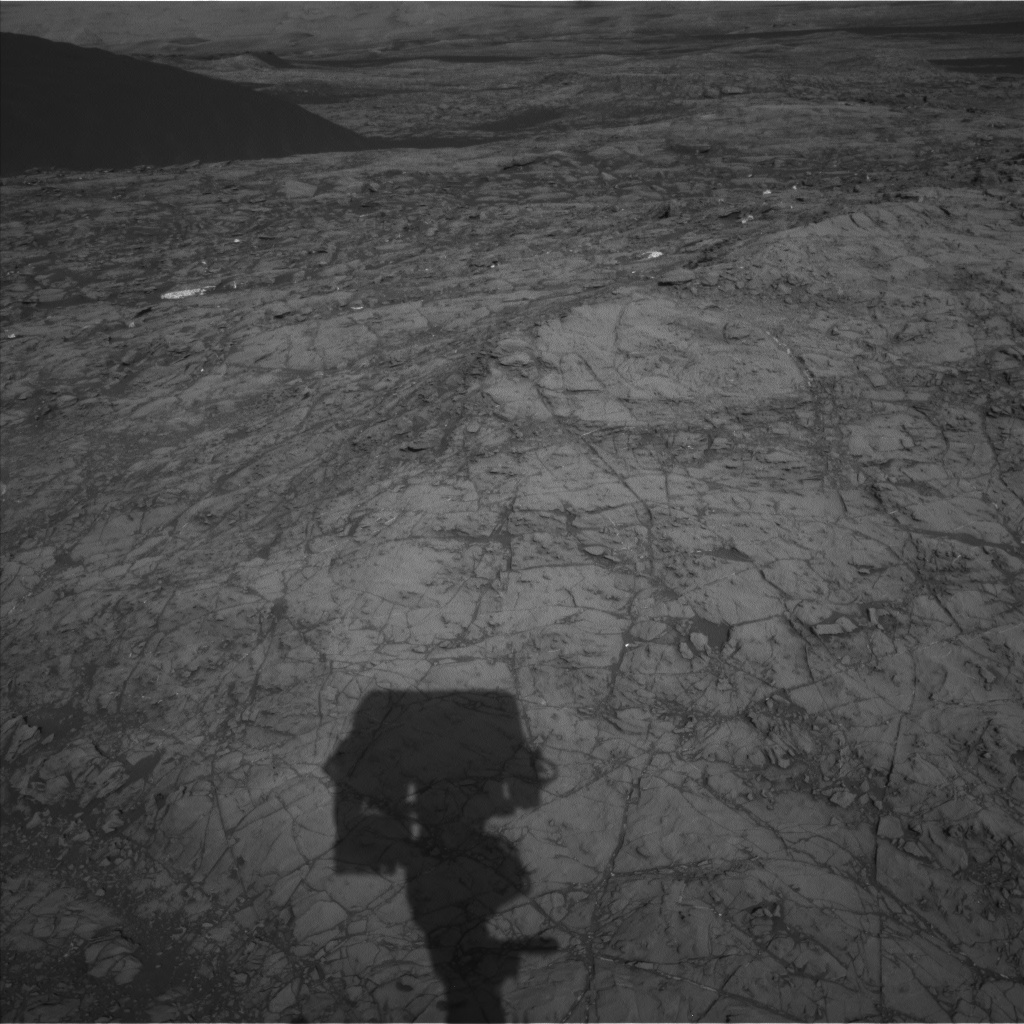

In [26]:
import numpy as np
from PIL import Image

sample_index = 10

row = train_dataset[sample_index]

image, label = prepare(row)

print("Image shape:", image.shape)

print("Label shape:", label.shape)

print("Unique label values:", np.unique(label))

display(Image.fromarray(image))

# **Class Imbalance and Baseline**

In [27]:
from tqdm.auto import tqdm
import numpy as np

IGNORE = 255

CLASSES = [
    "Soil",
    "Bedrock",
    "Sand",
    "Big Rock"
]

In [28]:
NUM_SAMPLES = min(2000, len(train_dataset))

counts = np.zeros(4,dtype=np.int64)

print("Images selected:",NUM_SAMPLES)

Images selected: 2000


In [29]:
for i in tqdm(range(NUM_SAMPLES)):
  row = train_dataset[i]

  _,label = prepare(row)

  valid_pixels = label[label != IGNORE]

  pixel_counts = np.bincount(
      valid_pixels.ravel(),
      minlength=4
  )

  counts += pixel_counts[:4]

  0%|          | 0/2000 [00:00<?, ?it/s]

In [30]:
total_pixels = counts.sum()

class_freq = counts/total_pixels

weights = 1 - class_freq

print("\nCLASS DISTRIBUTION\n")

for i in range(4):
    print(f"{CLASSES[i]}:")
    print("Pixels:", counts[i])
    print("Percentage:", round(class_freq[i] * 100, 3))
    print("Weight:", round(weights[i], 5))
    print()


CLASS DISTRIBUTION

Soil:
Pixels: 437751231
Percentage: 37.873
Weight: 0.62127

Bedrock:
Pixels: 566301634
Percentage: 48.994
Weight: 0.51006

Sand:
Pixels: 139817179
Percentage: 12.096
Weight: 0.87904

Big Rock:
Pixels: 11983703
Percentage: 1.037
Weight: 0.98963



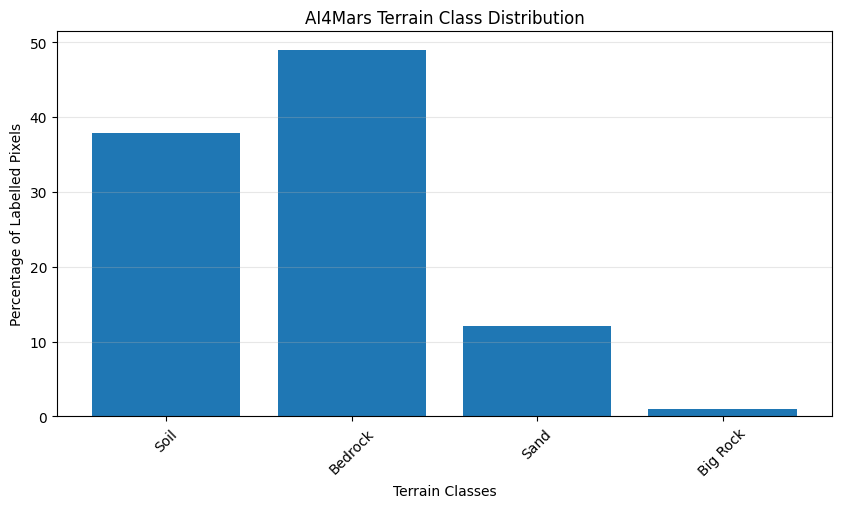

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.bar(CLASSES, class_freq*100)

plt.title("AI4Mars Terrain Class Distribution")
plt.xlabel("Terrain Classes")
plt.ylabel("Percentage of Labelled Pixels")

plt.xticks(rotation=45)
plt.grid(axis="y",alpha=0.3)

plt.show()

In [32]:
print("Class weights:", weights)

print("\nSum of class frequencies:", class_freq.sum())

print("Sum of class weights:", weights.sum())

print("All weights positive:", np.all(weights > 0))

Class weights: [0.62127455 0.51005771 0.87903558 0.98963216]

Sum of class frequencies: 1.0
Sum of class weights: 3.0
All weights positive: True


In [33]:
NUM_CLASSES = 4

confusion_matrix = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)

print("Confusion matrix:", confusion_matrix)

Confusion matrix: [[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]


In [46]:
from tqdm.auto import tqdm

for i in tqdm(range(len(val_dataset))):

  row = val_dataset[i]

  _,label = prepare(row)

  prediction = np.zeros_like(label)

  valid = label != IGNORE

  batch_cm = np.bincount(
      NUM_CLASSES * label[valid] + prediction[valid],
      minlength=NUM_CLASSES ** 2
  ).reshape(NUM_CLASSES, NUM_CLASSES)

  confusion_matrix += batch_cm

  0%|          | 0/1607 [00:00<?, ?it/s]

In [47]:
intersection = np.diag(confusion_matrix)

actual_pixels = confusion_matrix.sum(axis=1)

predicted_pixels = confusion_matrix.sum(axis=0)

union = actual_pixels + predicted_pixels - intersection

iou = intersection / (union + 1e-9)

mean_iou = np.mean(iou)

pixel_accuracy = intersection.sum() / confusion_matrix.sum()

print("\nBASELINE RESULTS\n")

for i in range(NUM_CLASSES):

    print(f"{CLASSES[i]} IoU: {iou[i]:.4f}")

print("\nMean IoU:", round(mean_iou, 4))

print("Pixel Accuracy:", round(pixel_accuracy, 4))


BASELINE RESULTS

Soil IoU: 0.3784
Bedrock IoU: 0.0000
Sand IoU: 0.0000
Big Rock IoU: 0.0000

Mean IoU: 0.0946
Pixel Accuracy: 0.3784


In [48]:
print("BASELINE CONFUSION MATRIX\n")

print(confusion_matrix)

print("\nActual pixels per class:")
print(confusion_matrix.sum(axis=1))

print("\nPredicted pixels per class:")
print(confusion_matrix.sum(axis=0))

BASELINE CONFUSION MATRIX

[[714484382         0         0         0]
 [930866234         0         0         0]
 [226859488         0         0         0]
 [ 15896552         0         0         0]]

Actual pixels per class:
[714484382 930866234 226859488  15896552]

Predicted pixels per class:
[1888106656          0          0          0]


# PyTorch Dataset and DataLoader

In [49]:
import torch
import numpy as np

my_arr = np.array([
    [1,2,3],
    [4,5,6]
])

print("Numpy Array:")
print(my_arr)

my_tensor = torch.tensor(my_arr)

print("\nPyTorch Tensor:")
print(my_tensor)

Numpy Array:
[[1 2 3]
 [4 5 6]]

PyTorch Tensor:
tensor([[1, 2, 3],
        [4, 5, 6]])


In [50]:
row = train_dataset[0]

image_np, label_np = prepare(row)

print("Original image shape:", image_np.shape)

print("Original label shape:", label_np.shape)

Original image shape: (1024, 1024, 3)
Original label shape: (1024, 1024)


In [51]:
image_tensor = torch.from_numpy(image_np)

print("Tensor shape:", image_tensor.shape)

print("Tensor dtype:", image_tensor.dtype)

Tensor shape: torch.Size([1024, 1024, 3])
Tensor dtype: torch.uint8


In [52]:
image_tensor = image_tensor.permute(2, 0, 1)

print("New image shape:", image_tensor.shape)

New image shape: torch.Size([3, 1024, 1024])


In [53]:
image_tensor = image_tensor.float() / 255.0

print("Data Type:", image_tensor.dtype)

print("Minimum Pixel Value:", image_tensor.min().item())

print("Maximum Pixel Value:", image_tensor.max().item())

Data Type: torch.float32
Minimum Pixel Value: 0.019607843831181526
Maximum Pixel Value: 1.0


In [54]:
label_tensor = torch.from_numpy(label_np.copy()).long()

print("Label Tensor Shape:", label_tensor.shape)

print("Label Tensor Dtype:", label_tensor.dtype)

print("Unique Values:", torch.unique(label_tensor))

Label Tensor Shape: torch.Size([1024, 1024])
Label Tensor Dtype: torch.int64
Unique Values: tensor([  0,   1,   2,   3, 255])


In [55]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

image_gpu = image_tensor.to(device)

label_gpu = label_tensor.to(device)

print("Image device:", image_gpu.device)

print("Label device:", label_gpu.device)

Selected device: cuda
Image device: cuda:0
Label device: cuda:0


Image Resizing and Normalization

In [56]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

TARGET_SIZE = 512

row = train_dataset[0]

image_np,label_np = prepare(row)

resized_image = np.array(
    Image.fromarray(image_np).resize(
        (TARGET_SIZE,TARGET_SIZE),
        resample= Image.Resampling.BILINEAR
    )
)

resized_label = np.array(
    Image.fromarray(label_np.astype(np.uint8)).resize(
        (TARGET_SIZE,TARGET_SIZE),
        resample= Image.Resampling.NEAREST
    )
)
print("Original image:", image_np.shape)
print("Resized image:", resized_image.shape)

print("\nOriginal label:", label_np.shape)
print("Resized label:", resized_label.shape)

print("\nUnique mask values:", np.unique(resized_label))

Original image: (1024, 1024, 3)
Resized image: (512, 512, 3)

Original label: (1024, 1024)
Resized label: (512, 512)

Unique mask values: [  0   1   2   3 255]


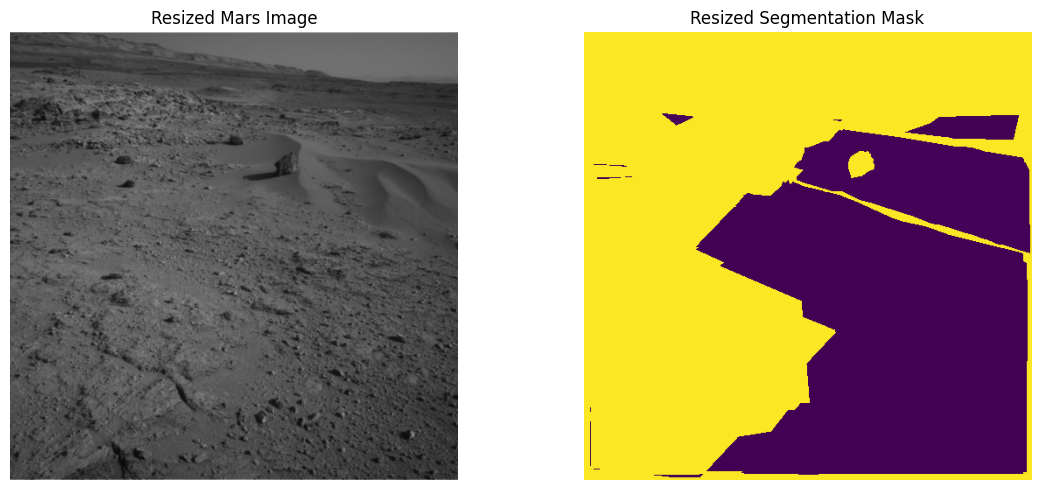

In [57]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(resized_image)
plt.title("Resized Mars Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_label)
plt.title("Resized Segmentation Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [58]:
import torch

image_tensor = torch.from_numpy(
    resized_image.copy()
)

image_tensor = image_tensor.permute(2,0,1)

image_tensor = image_tensor.float()/255.0

mean = torch.tensor(
   [0.485,0.456,0.406]
).view(3,1,1)

std = torch.tensor(
    [0.229,0.224,0.225]
).view(3,1,1)

normalized_image = (image_tensor - mean) / std
print("Shape:", normalized_image.shape)

print("Data type:", normalized_image.dtype)

print("Minimum value:", normalized_image.min().item())

print("Maximum value:", normalized_image.max().item())


Shape: torch.Size([3, 512, 512])
Data type: torch.float32
Minimum value: -1.9637812376022339
Maximum value: 1.2805230617523193


In [60]:
label_tensor = torch.from_numpy(
    resized_label.copy()
).long()

print("Label shape:",label_tensor.shape)

print("Label dtype:",label_tensor.dtype)

print("Unique values:",torch.unique(label_tensor))

allowed_values = torch.tensor(
    [0,1,2,3,255]
)

assert torch.isin(
    torch.unique(label_tensor),
    allowed_values
).all()

print("Segmentation mask validation passed!")

Label shape: torch.Size([512, 512])
Label dtype: torch.int64
Unique values: tensor([  0,   1,   2,   3, 255])
Segmentation mask validation passed!


Custom PyTorch Dataset

In [61]:
import torch

from torch.utils.data import Dataset

import numpy as np

from PIL import Image

In [62]:
class MarsDataset(Dataset):
  def __init__(self,dataset,image_size=512):
     self.dataset = dataset
     self.image_size = image_size

     self.mean = torch.tensor(
         [0.485,0.456,0.406]
     ).view(3,1,1)

     self.std = torch.tensor(
         [0.229,0.224,0.225]
     ).view(3,1,1)

  def __len__(self):
    return len(self.dataset)

  def __getitem__(self, index):
     row = self.dataset[index]

     image, label = prepare(row)

     image = Image.fromarray(image).resize(
         (self.image_size,self.image_size),
         resample=Image.Resampling.BILINEAR
     )

     label = Image.fromarray(
         label.astype(np.uint8)
     ).resize(
         (self.image_size,self.image_size),
         resample= Image.Resampling.NEAREST
     )

     image = np.array(image)

     image = torch.from_numpy(
         image.copy()
     )

     image = image.permute(2,0,1)

     image = image.float() / 255.0

     image = (image-self.mean) / self.std

     label = torch.from_numpy(
         np.array(label,dtype=np.int64).copy()
     ).long()

     return image, label

In [63]:
mars_train_dataset = MarsDataset(
    train_dataset,
    image_size=512
)
mars_val_dataset = MarsDataset(
    val_dataset,
    image_size=512
)

print("Training samples:", len(mars_train_dataset))

print("Validation samples:", len(mars_val_dataset))

Training samples: 14457
Validation samples: 1607


In [64]:
sample_image, sample_label = mars_train_dataset[0]

print("Image shape:", sample_image.shape)
print("Image dtype:", sample_image.dtype)

print("\nLabel shape:", sample_label.shape)
print("Label dtype:", sample_label.dtype)

print("\nUnique label values:", torch.unique(sample_label))

Image shape: torch.Size([3, 512, 512])
Image dtype: torch.float32

Label shape: torch.Size([512, 512])
Label dtype: torch.int64

Unique label values: tensor([  0,   1,   2,   3, 255])


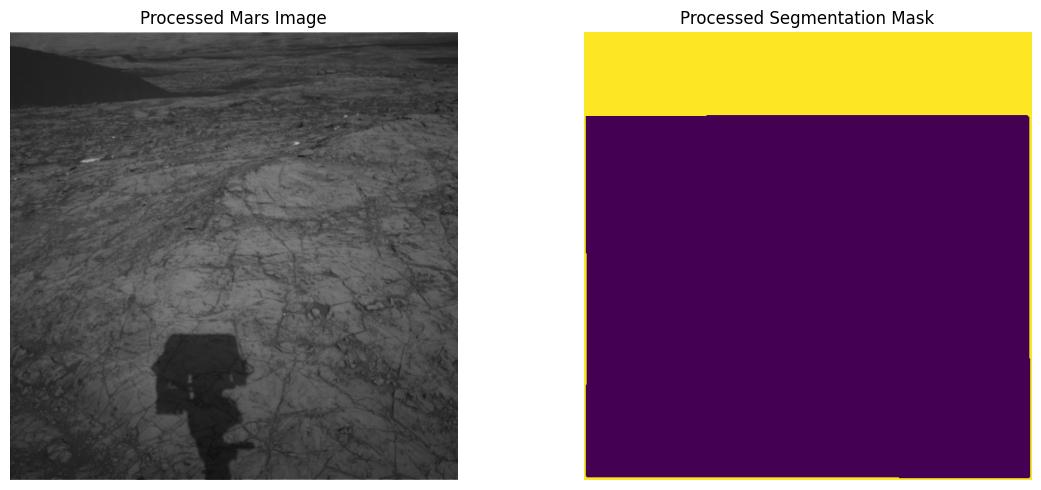

In [65]:
import matplotlib.pyplot as plt

image, mask = mars_train_dataset[10]

image_display = image.permute(1, 2, 0).numpy()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image_display = image_display * std + mean
image_display = np.clip(image_display, 0, 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_display)
plt.title("Processed Mars Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask.numpy())
plt.title("Processed Segmentation Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

PyTorch DataLoader

In [66]:
from torch.utils.data import DataLoader
import torch

BATCH_SIZE = 4

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:",device)
print("Batch size:", BATCH_SIZE)

Device: cuda
Batch size: 4


In [67]:
train_loader = DataLoader(
    dataset=mars_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

In [68]:
val_loader = DataLoader(
    dataset=mars_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

In [69]:
images, masks = next(iter(train_loader))

print("IMAGE BATCH")

print("Shape:", images.shape)
print("Data type:", images.dtype)

print("\nMASK BATCH")

print("Shape:", masks.shape)
print("Data type:", masks.dtype)

print("\nUnique mask values:", torch.unique(masks))

IMAGE BATCH
Shape: torch.Size([4, 3, 512, 512])
Data type: torch.float32

MASK BATCH
Shape: torch.Size([4, 512, 512])
Data type: torch.int64

Unique mask values: tensor([  0,   1,   2, 255])


In [70]:
print("Training batches:", len(train_loader))

print("Validation batches:", len(val_loader))

print("Training samples:", len(train_loader.dataset))

print("Validation samples:", len(val_loader.dataset))

Training batches: 3615
Validation batches: 402
Training samples: 14457
Validation samples: 1607
